In [1]:
import pandas as pd

In [3]:
brands=pd.read_csv("raw_data/brands.csv")

In [4]:
brands

,brand_id,brand_name
0,1,Electra
1,2,Haro
2,3,Heller
3,4,Pure Cycles
4,5,Ritchey
5,6,Strider
6,7,Sun Bicycles
7,8,Surly
8,9,Trek


In [5]:
brands.duplicated().sum()

np.int64(0)

In [6]:
brands.shape

(9, 2)

In [7]:
brands.isnull().sum()

brand_id      0
brand_name    0
dtype: int64

In [8]:
brands.columns.tolist()

['brand_id', 'brand_name']

In [9]:
brands.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   brand_id    9 non-null      int64
 1   brand_name  9 non-null      str  
dtypes: int64(1), str(1)
memory usage: 276.0 bytes


In [10]:
brands["brand_id"].value_counts()

brand_id
1    1
2    1
3    1
4    1
5    1
6    1
7    1
8    1
9    1
Name: count, dtype: int64

In [11]:
(brands["brand_name"]!=brands["brand_name"].str.strip()).sum()

np.int64(0)

In [12]:
brands.to_csv("cleaned_data/brands_cleaned.csv",index=False)

In [13]:
categories=pd.read_csv("raw_data/categories.csv")

In [14]:
categories

,category_id,category_name
0,1,Children Bicycles
1,2,Comfort Bicycles
2,3,Cruisers Bicycles
3,4,Cyclocross Bicycles
4,5,Electric Bikes
5,6,Mountain Bikes
6,7,Road Bikes


In [15]:
categories.duplicated().sum()

np.int64(0)

In [16]:
categories.isnull().sum()

category_id      0
category_name    0
dtype: int64

In [17]:
categories.shape

(7, 2)

In [18]:
categories.info()

<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   category_id    7 non-null      int64
 1   category_name  7 non-null      str  
dtypes: int64(1), str(1)
memory usage: 244.0 bytes


In [19]:
categories["category_id"].value_counts()

category_id
1    1
2    1
3    1
4    1
5    1
6    1
7    1
Name: count, dtype: int64

In [20]:
(categories["category_name"]!=categories["category_name"].str.strip()).sum()

np.int64(0)

In [21]:
categories.to_csv("cleaned_data/categories_cleaned.csv",index=False)

In [22]:
customers=pd.read_csv("raw_data/customers.csv")

In [23]:
customers

,customer_id,first_name,last_name,phone,email,street,city,state,zip_code
0,1,Debra,Burks,NaN,debra.burks@yahoo.com,9273 Thorne Ave.,Orchard Park,NY,14127
1,2,Kasha,Todd,NaN,kasha.todd@yahoo.com,910 Vine Street,Campbell,CA,95008
2,3,Tameka,Fisher,NaN,tameka.fisher@aol.com,769C Honey Creek St.,Redondo Beach,CA,90278
3,4,Daryl,Spence,NaN,daryl.spence@aol.com,988 Pearl Lane,Uniondale,NY,11553
4,5,Charolette,Rice,(916) 381-6003,charolette.rice@msn.com,107 River Dr.,Sacramento,CA,95820
...,...,...,...,...,...,...,...,...,...
1440,1441,Jamaal,Morrison,NaN,jamaal.morrison@msn.com,796 SE. Nut Swamp St.,Staten Island,NY,10301
1441,1442,Cassie,Cline,NaN,cassie.cline@gmail.com,947 Lafayette Drive,Brooklyn,NY,11201
1442,1443,Lezlie,Lamb,NaN,lezlie.lamb@gmail.com,401 Brandywine Street,Central Islip,NY,11722
1443,1444,Ivette,Estes,NaN,ivette.estes@gmail.com,88 N. Canterbury Ave.,Canandaigua,NY,14424


In [24]:
customers.shape

(1445, 9)

In [25]:
customers.duplicated().sum()

np.int64(0)

In [26]:
customers.isnull().sum()

customer_id       0
first_name        0
last_name         0
phone          1267
email             0
street            0
city              0
state             0
zip_code          0
dtype: int64

In [27]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 1445 entries, 0 to 1444
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   customer_id  1445 non-null   int64
 1   first_name   1445 non-null   str  
 2   last_name    1445 non-null   str  
 3   phone        178 non-null    str  
 4   email        1445 non-null   str  
 5   street       1445 non-null   str  
 6   city         1445 non-null   str  
 7   state        1445 non-null   str  
 8   zip_code     1445 non-null   int64
dtypes: int64(2), str(7)
memory usage: 101.7 KB


In [28]:
customers["zip_code"].nunique()

195

In [29]:
customers.groupby("zip_code")["city"].nunique().sort_values(ascending=False)

zip_code
10002    1
10301    1
10451    1
10512    1
10541    1
        ..
95127    1
95301    1
95677    1
95820    1
95993    1
Name: city, Length: 195, dtype: int64

In [30]:
customers.groupby("zip_code")["city"].nunique().loc[lambda x: x > 1]

Series([], Name: city, dtype: int64)

## ZIP Code Validation

Checked whether each ZIP code is associated with multiple city names using `groupby()` and `nunique()`.

No ZIP codes were associated with multiple different city names in the dataset. Repeated ZIP codes were retained because multiple records can share the same ZIP code.

Note: This check verifies consistency within the dataset but does not confirm the actual geographic accuracy of each ZIP code.

In [31]:
customers["customer_id"].nunique()

1445

In [32]:
print(customers[customers["phone"].isnull()])

      customer_id first_name last_name phone                     email  \
0               1      Debra     Burks   NaN     debra.burks@yahoo.com   
1               2      Kasha      Todd   NaN      kasha.todd@yahoo.com   
2               3     Tameka    Fisher   NaN     tameka.fisher@aol.com   
3               4      Daryl    Spence   NaN      daryl.spence@aol.com   
5               6    Lyndsey      Bean   NaN  lyndsey.bean@hotmail.com   
...           ...        ...       ...   ...                       ...   
1440         1441     Jamaal  Morrison   NaN   jamaal.morrison@msn.com   
1441         1442     Cassie     Cline   NaN    cassie.cline@gmail.com   
1442         1443     Lezlie      Lamb   NaN     lezlie.lamb@gmail.com   
1443         1444     Ivette     Estes   NaN    ivette.estes@gmail.com   
1444         1445      Ester   Acevedo   NaN   ester.acevedo@gmail.com   

                      street           city state  zip_code  
0          9273 Thorne Ave.    Orchard Park    NY

In [33]:
customers["phone"].isnull().sum()

np.int64(1267)

In [34]:
customers["phone"]=customers["phone"].fillna("Unknown")

In [35]:
str_cols=["first_name","last_name","phone","email","street","city","state"]
for col in str_cols:
    print(col,(customers[col].dropna()!=customers[col].dropna().str.strip()).sum())

first_name 0
last_name 0
phone 0
email 0
street 1445
city 0
state 0


In [36]:
customers["street"].head().apply(repr)

0        '9273 Thorne Ave. '
1         '910 Vine Street '
2    '769C Honey Creek St. '
3          '988 Pearl Lane '
4           '107 River Dr. '
Name: street, dtype: str

In [37]:
customers["street"]=customers["street"].str.strip()

In [38]:
customers["first_name"] = customers["first_name"].str.title()
customers["last_name"] = customers["last_name"].str.title()
customers["city"] = customers["city"].str.title()
customers["street"] = customers["street"].str.title()
customers["state"] = customers["state"].str.upper()



In [39]:
customers["street"] = customers["street"].str.replace(
    r"(\d)(St|Nd|Rd|Th)\b",
    lambda m: m.group(1) + m.group(2).lower(),
    regex=True
)

In [40]:
customers[customers["street"].str.contains(r"\d(?:St|Nd|Rd|Th)\b")]

,customer_id,first_name,last_name,phone,email,street,city,state,zip_code


In [41]:
customers

,customer_id,first_name,last_name,phone,email,street,city,state,zip_code
0,1,Debra,Burks,Unknown,debra.burks@yahoo.com,9273 Thorne Ave.,Orchard Park,NY,14127
1,2,Kasha,Todd,Unknown,kasha.todd@yahoo.com,910 Vine Street,Campbell,CA,95008
2,3,Tameka,Fisher,Unknown,tameka.fisher@aol.com,769C Honey Creek St.,Redondo Beach,CA,90278
3,4,Daryl,Spence,Unknown,daryl.spence@aol.com,988 Pearl Lane,Uniondale,NY,11553
4,5,Charolette,Rice,(916) 381-6003,charolette.rice@msn.com,107 River Dr.,Sacramento,CA,95820
...,...,...,...,...,...,...,...,...,...
1440,1441,Jamaal,Morrison,Unknown,jamaal.morrison@msn.com,796 Se. Nut Swamp St.,Staten Island,NY,10301
1441,1442,Cassie,Cline,Unknown,cassie.cline@gmail.com,947 Lafayette Drive,Brooklyn,NY,11201
1442,1443,Lezlie,Lamb,Unknown,lezlie.lamb@gmail.com,401 Brandywine Street,Central Islip,NY,11722
1443,1444,Ivette,Estes,Unknown,ivette.estes@gmail.com,88 N. Canterbury Ave.,Canandaigua,NY,14424


In [42]:
customers.to_csv("cleaned_data/customers_cleaned.csv",index=False)

In [43]:
order_items=pd.read_csv("raw_data/order_items.csv")

In [44]:
order_items

,order_id,item_id,product_id,quantity,list_price,discount
0,1,1,20,1,599.99,0.20
1,1,2,8,2,1799.99,0.07
2,1,3,10,2,1549.00,0.05
3,1,4,16,2,599.99,0.05
4,1,5,4,1,2899.99,0.20
...,...,...,...,...,...,...
4717,1614,2,159,2,2299.99,0.07
4718,1614,3,213,2,269.99,0.20
4719,1615,1,197,2,2299.99,0.20
4720,1615,2,214,1,899.99,0.07


In [45]:
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 4722 entries, 0 to 4721
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   order_id    4722 non-null   int64  
 1   item_id     4722 non-null   int64  
 2   product_id  4722 non-null   int64  
 3   quantity    4722 non-null   int64  
 4   list_price  4722 non-null   float64
 5   discount    4722 non-null   float64
dtypes: float64(2), int64(4)
memory usage: 221.5 KB


In [46]:
order_items.shape

(4722, 6)

In [47]:
order_items["order_id"].nunique()

1615

In [48]:
order_items["order_id"].value_counts()

order_id
1       5
6       5
18      5
25      5
29      5
       ..
1599    1
1603    1
1604    1
1607    1
1608    1
Name: count, Length: 1615, dtype: int64

In [49]:
order_items["item_id"].nunique()


5

In [50]:
order_items["product_id"].nunique()


307

In [51]:
order_items.duplicated(subset=['order_id', 'item_id']).sum()

np.int64(0)

In [52]:
order_items.duplicated(subset=['order_id', 'product_id']).sum()

np.int64(0)

In [53]:
order_items.duplicated().sum()

np.int64(0)

In [54]:
order_items.isnull().sum()

order_id      0
item_id       0
product_id    0
quantity      0
list_price    0
discount      0
dtype: int64

In [55]:
order_items.to_csv("cleaned_data/order_items_cleaned.csv",index=False)

In [56]:
orders=pd.read_csv("raw_data/orders.csv")

In [57]:
orders

,order_id,customer_id,order_status,order_date,required_date,shipped_date,store_id,staff_id
0,1,259,4,2016-01-01,2016-01-03,2016-01-03,1,2
1,2,1212,4,2016-01-01,2016-01-04,2016-01-03,2,6
2,3,523,4,2016-01-02,2016-01-05,2016-01-03,2,7
3,4,175,4,2016-01-03,2016-01-04,2016-01-05,1,3
4,5,1324,4,2016-01-03,2016-01-06,2016-01-06,2,6
...,...,...,...,...,...,...,...,...
1610,1611,6,3,2018-09-06,2018-09-06,NaN,2,7
1611,1612,3,3,2018-10-21,2018-10-21,NaN,1,3
1612,1613,1,3,2018-11-18,2018-11-18,NaN,2,6
1613,1614,135,3,2018-11-28,2018-11-28,NaN,3,8


In [58]:
orders.shape

(1615, 8)

In [59]:
orders.duplicated().sum()

np.int64(0)

In [60]:
orders.isnull().sum()

order_id           0
customer_id        0
order_status       0
order_date         0
required_date      0
shipped_date     170
store_id           0
staff_id           0
dtype: int64

In [61]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 1615 entries, 0 to 1614
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   order_id       1615 non-null   int64
 1   customer_id    1615 non-null   int64
 2   order_status   1615 non-null   int64
 3   order_date     1615 non-null   str  
 4   required_date  1615 non-null   str  
 5   shipped_date   1445 non-null   str  
 6   store_id       1615 non-null   int64
 7   staff_id       1615 non-null   int64
dtypes: int64(5), str(3)
memory usage: 101.1 KB


In [62]:
orders["order_id"].nunique()

1615

In [63]:
orders["customer_id"].nunique()

1445

In [64]:
orders["customer_id"].unique()

array([ 259, 1212,  523, ...,   35,  180,  392], shape=(1445,))

In [65]:
orders["customer_id"].value_counts().head(10)

customer_id
50    3
9     3
7     3
12    3
46    3
43    3
32    3
31    3
24    3
13    3
Name: count, dtype: int64

In [66]:
orders["store_id"].nunique()

3

In [67]:
orders["store_id"].unique()

array([1, 2, 3])

In [68]:
orders["store_id"].value_counts()

store_id
2    1093
1     348
3     174
Name: count, dtype: int64

In [69]:
orders["staff_id"].nunique()

6

In [70]:
orders["staff_id"].unique()

array([2, 6, 7, 3, 8, 9])

In [71]:
orders["staff_id"].value_counts()

staff_id
6    553
7    540
3    184
2    164
8     88
9     86
Name: count, dtype: int64

In [72]:
orders["order_status"].dtype

dtype('int64')

In [73]:
orders["order_date"].head(30)

0     2016-01-01
1     2016-01-01
2     2016-01-02
3     2016-01-03
4     2016-01-03
5     2016-01-04
6     2016-01-04
7     2016-01-04
8     2016-01-05
9     2016-01-05
10    2016-01-05
11    2016-01-06
12    2016-01-08
13    2016-01-09
14    2016-01-09
15    2016-01-12
16    2016-01-12
17    2016-01-14
18    2016-01-14
19    2016-01-14
20    2016-01-15
21    2016-01-16
22    2016-01-16
23    2016-01-18
24    2016-01-18
25    2016-01-18
26    2016-01-19
27    2016-01-19
28    2016-01-20
29    2016-01-20
Name: order_date, dtype: str

In [74]:
orders["order_date"] = pd.to_datetime(orders["order_date"], format="%Y-%m-%d")

In [75]:
orders["shipped_date"].head(20)

0     2016-01-03
1     2016-01-03
2     2016-01-03
3     2016-01-05
4     2016-01-06
5     2016-01-05
6     2016-01-05
7     2016-01-05
8     2016-01-08
9     2016-01-06
10    2016-01-07
11    2016-01-09
12    2016-01-11
13    2016-01-12
14    2016-01-12
15    2016-01-15
16    2016-01-14
17    2016-01-15
18    2016-01-16
19    2016-01-17
Name: shipped_date, dtype: str

In [76]:
before = orders['shipped_date'].isnull().sum()

In [77]:
orders["shipped_date"] = pd.to_datetime(orders["shipped_date"], format="%Y-%m-%d")


In [78]:
after = orders['shipped_date'].isnull().sum()
print(before, after)

170 170


In [79]:
orders["shipped_date"].isnull().sum()

np.int64(170)

In [80]:
orders["required_date"].head(20)

0     2016-01-03
1     2016-01-04
2     2016-01-05
3     2016-01-04
4     2016-01-06
5     2016-01-07
6     2016-01-07
7     2016-01-05
8     2016-01-08
9     2016-01-06
10    2016-01-08
11    2016-01-08
12    2016-01-11
13    2016-01-11
14    2016-01-10
15    2016-01-15
16    2016-01-14
17    2016-01-17
18    2016-01-17
19    2016-01-16
Name: required_date, dtype: str

In [81]:
orders["required_date"] = pd.to_datetime(orders["required_date"], format="%Y-%m-%d")


In [82]:
print(orders[orders["shipped_date"].isnull()])

      order_id  customer_id  order_status order_date required_date  \
69          70           50             3 2016-02-11    2016-02-11   
75          76            9             3 2016-02-16    2016-02-16   
157        158          117             3 2016-04-04    2016-04-04   
184        185           24             3 2016-04-20    2016-04-20   
238        239           13             3 2016-05-27    2016-05-27   
...        ...          ...           ...        ...           ...   
1610      1611            6             3 2018-09-06    2018-09-06   
1611      1612            3             3 2018-10-21    2018-10-21   
1612      1613            1             3 2018-11-18    2018-11-18   
1613      1614          135             3 2018-11-28    2018-11-28   
1614      1615          136             3 2018-12-28    2018-12-28   

     shipped_date  store_id  staff_id  
69            NaT         3         9  
75            NaT         2         6  
157           NaT         3         9  

In [83]:
orders["order_status"].unique()

array([4, 3, 2, 1])

In [84]:
status_map = {1: "Pending", 2: "Processing", 3: "Rejected", 4: "Completed"}

orders["order_status"] = orders["order_status"].map(status_map)

In [85]:
print(orders["order_status"].value_counts())

order_status
Completed     1445
Processing      63
Pending         62
Rejected        45
Name: count, dtype: int64


In [86]:
orders["order_status"].dtype

<StringDtype(storage='python', na_value=nan)>

In [87]:
orders[orders["shipped_date"].isnull()]["order_status"].value_counts()

order_status
Processing    63
Pending       62
Rejected      45
Name: count, dtype: int64

In [88]:
orders[orders["order_status"] == "Rejected"]["shipped_date"].isnull().sum()

np.int64(45)

In [89]:
orders[orders["order_status"] == "Processing"]["shipped_date"].isnull().sum()


np.int64(63)

In [90]:
orders[orders["order_status"] == "Pending"]["shipped_date"].isnull().sum()


np.int64(62)

In [91]:
orders[orders["order_status"] == "Completed"]["shipped_date"].isnull().sum()


np.int64(0)

In [92]:
orders["shipped"] = orders["shipped_date"].notnull()
pd.crosstab(orders["order_status"], orders["shipped"])


shipped,False,True
order_status,,
Completed,0,1445
Pending,62,0
Processing,63,0
Rejected,45,0


Note: 170 orders have no shipped date. These orders are Pending,
Processing, and Rejected, so they were never shipped.
This is expected, so I kept them as null.

In [93]:
orders = orders.drop(columns=["shipped"])

In [94]:
orders.to_csv("cleaned_data/orders_cleaned.csv",index=False,date_format="%Y-%m-%d")

In [95]:
products=pd.read_csv("raw_data/products.csv")

In [96]:
products

,product_id,product_name,brand_id,category_id,model_year,list_price
0,1,Trek 820 - 2016,9,6,2016,379.99
1,2,Ritchey Timberwolf Frameset - 2016,5,6,2016,749.99
2,3,Surly Wednesday Frameset - 2016,8,6,2016,999.99
3,4,Trek Fuel EX 8 29 - 2016,9,6,2016,2899.99
4,5,Heller Shagamaw Frame - 2016,3,6,2016,1320.99
...,...,...,...,...,...,...
316,317,Trek Checkpoint ALR 5 - 2019,9,7,2019,1999.99
317,318,Trek Checkpoint ALR 5 Women's - 2019,9,7,2019,1999.99
318,319,Trek Checkpoint SL 5 Women's - 2019,9,7,2019,2799.99
319,320,Trek Checkpoint SL 6 - 2019,9,7,2019,3799.99


In [97]:
products.shape

(321, 6)

In [98]:
products.duplicated().sum()

np.int64(0)

In [99]:
products.isnull().sum()

product_id      0
product_name    0
brand_id        0
category_id     0
model_year      0
list_price      0
dtype: int64

In [100]:
products["product_id"].nunique()

321

In [101]:
products["product_id"].is_unique

True

In [103]:
products["brand_id"].nunique()

9

In [104]:
products["brand_id"].value_counts()

brand_id
9    135
1    118
8     25
7     23
2     10
3      3
4      3
6      3
5      1
Name: count, dtype: int64

In [105]:
products["category_id"].nunique()

7

In [106]:
products["category_id"].value_counts()

category_id
3    78
6    60
7    60
1    59
2    30
5    24
4    10
Name: count, dtype: int64

In [107]:
(products["product_name"] != products["product_name"].str.strip()).sum()

np.int64(0)

In [108]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 321 entries, 0 to 320
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    321 non-null    int64  
 1   product_name  321 non-null    str    
 2   brand_id      321 non-null    int64  
 3   category_id   321 non-null    int64  
 4   model_year    321 non-null    int64  
 5   list_price    321 non-null    float64
dtypes: float64(1), int64(4), str(1)
memory usage: 15.2 KB


In [109]:
dup = products[products.duplicated(["product_name", "model_year"], keep=False)]
dup.sort_values("product_name")

,product_id,product_name,brand_id,category_id,model_year,list_price
12,13,Electra Cruiser 1 (24-Inch) - 2016,1,3,2016,269.99
20,21,Electra Cruiser 1 (24-Inch) - 2016,1,1,2016,269.99
226,227,Electra Cruiser 7D (24-Inch) Ladies' - 2016/2018,1,3,2018,319.99
280,281,Electra Cruiser 7D (24-Inch) Ladies' - 2016/2018,1,1,2018,319.99
13,14,Electra Girl's Hawaii 1 (16-inch) - 2015/2016,1,3,2016,269.99
21,22,Electra Girl's Hawaii 1 (16-inch) - 2015/2016,1,1,2016,269.99
75,76,"Electra Girl's Hawaii 1 16"" - 2017",1,3,2017,299.99
94,95,"Electra Girl's Hawaii 1 16"" - 2017",1,1,2017,299.99
304,305,Electra Townie Balloon 3i EQ - 2017/2018,1,2,2018,749.99
253,254,Electra Townie Balloon 3i EQ - 2017/2018,1,3,2018,749.99


30 products share the same name and model year but have different category IDs. The same bike is listed under more than one category, so they were kept.

In [110]:
products["product_name"].nunique()

291

In [111]:
products["product_name"].value_counts()

product_name
Electra Townie Go! 8i - 2017/2018                3
Electra Townie Original 21D - 2016               2
Electra Cruiser 1 (24-Inch) - 2016               2
Electra Girl's Hawaii 1 (16-inch) - 2015/2016    2
Electra Townie Original 7D EQ - 2016             2
                                                ..
Trek Checkpoint ALR 5 - 2019                     1
Trek Checkpoint ALR 5 Women's - 2019             1
Trek Checkpoint SL 5 Women's - 2019              1
Trek Checkpoint SL 6 - 2019                      1
Trek Checkpoint ALR Frameset - 2019              1
Name: count, Length: 291, dtype: int64

In [112]:
products.to_csv("cleaned_data/products_cleaned.csv",index=False,date_format="%Y-%m-%d")

In [113]:
staffs=pd.read_csv("raw_data/staffs.csv")

In [114]:
staffs

,staff_id,first_name,last_name,email,phone,active,store_id,manager_id
0,1,Fabiola,Jackson,fabiola.jackson@bikes.shop,(831) 555-5554,1,1,NaN
1,2,Mireya,Copeland,mireya.copeland@bikes.shop,(831) 555-5555,1,1,1.0
2,3,Genna,Serrano,genna.serrano@bikes.shop,(831) 555-5556,1,1,2.0
3,4,Virgie,Wiggins,virgie.wiggins@bikes.shop,(831) 555-5557,1,1,2.0
4,5,Jannette,David,jannette.david@bikes.shop,(516) 379-4444,1,2,1.0
5,6,Marcelene,Boyer,marcelene.boyer@bikes.shop,(516) 379-4445,1,2,5.0
6,7,Venita,Daniel,venita.daniel@bikes.shop,(516) 379-4446,1,2,5.0
7,8,Kali,Vargas,kali.vargas@bikes.shop,(972) 530-5555,1,3,1.0
8,9,Layla,Terrell,layla.terrell@bikes.shop,(972) 530-5556,1,3,7.0
9,10,Bernardine,Houston,bernardine.houston@bikes.shop,(972) 530-5557,1,3,7.0


In [116]:
staffs.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   staff_id    10 non-null     int64  
 1   first_name  10 non-null     str    
 2   last_name   10 non-null     str    
 3   email       10 non-null     str    
 4   phone       10 non-null     str    
 5   active      10 non-null     int64  
 6   store_id    10 non-null     int64  
 7   manager_id  9 non-null      float64
dtypes: float64(1), int64(3), str(4)
memory usage: 772.0 bytes


In [115]:
staffs.duplicated().sum()

np.int64(0)

In [117]:
staffs.isnull().sum()

staff_id      0
first_name    0
last_name     0
email         0
phone         0
active        0
store_id      0
manager_id    1
dtype: int64

In [119]:
staffs["manager_id"] = staffs["manager_id"].astype("Int64")

In [120]:
staffs.shape

(10, 8)

In [121]:
staffs["store_id"].nunique()

3

In [122]:
staffs["store_id"].value_counts()

store_id
1    4
2    3
3    3
Name: count, dtype: int64

In [123]:
orders["staff_id"].isin(staffs["staff_id"]).all()

np.True_

In [124]:
staffs["staff_id"].nunique()


10

In [125]:
staffs["manager_id"].nunique()

4

In [126]:
staffs["manager_id"].value_counts()

manager_id
1    3
2    2
5    2
7    2
Name: count, dtype: Int64

In [127]:
staffs[staffs["manager_id"].isnull()]

,staff_id,first_name,last_name,email,phone,active,store_id,manager_id
0,1,Fabiola,Jackson,fabiola.jackson@bikes.shop,(831) 555-5554,1,1,<NA>


In [128]:
staffs[["staff_id", "first_name", "last_name","store_id", "manager_id"]]

,staff_id,first_name,last_name,store_id,manager_id
0,1,Fabiola,Jackson,1,<NA>
1,2,Mireya,Copeland,1,1
2,3,Genna,Serrano,1,2
3,4,Virgie,Wiggins,1,2
4,5,Jannette,David,2,1
5,6,Marcelene,Boyer,2,5
6,7,Venita,Daniel,2,5
7,8,Kali,Vargas,3,1
8,9,Layla,Terrell,3,7
9,10,Bernardine,Houston,3,7



### Handling Missing Manager ID

One missing value was identified in the `manager_id` column for Fabiola Jackson (staff ID 1). Other employees report to staff ID 1, suggesting that Fabiola may be the top-level manager. Since the correct manager ID could not be confirmed, the missing value was retained rather than replaced with an assumed value.


In [129]:
staffs.to_csv("cleaned_data/staffs_cleaned.csv",index=False)

In [130]:
stocks=pd.read_csv("raw_data/stocks.csv")

In [131]:
stocks.shape

(939, 3)

In [132]:
stocks.duplicated().sum()

np.int64(0)

In [133]:
stocks.isnull().sum()

store_id      0
product_id    0
quantity      0
dtype: int64

In [134]:
stocks.info()

<class 'pandas.DataFrame'>
RangeIndex: 939 entries, 0 to 938
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   store_id    939 non-null    int64
 1   product_id  939 non-null    int64
 2   quantity    939 non-null    int64
dtypes: int64(3)
memory usage: 22.1 KB


In [135]:
stocks["store_id"].nunique()

3

In [136]:
stocks["product_id"].nunique()

313

In [137]:
stocks["product_id"].isin(products["product_id"]).all()

np.True_

In [138]:
stocks.to_csv("cleaned_data/stocks_cleaned.csv",index=False)

In [139]:
stores=pd.read_csv("raw_data/stores.csv")

In [140]:
stores.shape

(3, 8)

In [141]:
stores.duplicated().sum()

np.int64(0)

In [142]:
stores.isnull().sum()

store_id      0
store_name    0
phone         0
email         0
street        0
city          0
state         0
zip_code      0
dtype: int64

In [143]:
stores.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   store_id    3 non-null      int64
 1   store_name  3 non-null      str  
 2   phone       3 non-null      str  
 3   email       3 non-null      str  
 4   street      3 non-null      str  
 5   city        3 non-null      str  
 6   state       3 non-null      str  
 7   zip_code    3 non-null      int64
dtypes: int64(2), str(6)
memory usage: 324.0 bytes


In [144]:
stores["store_id"].nunique()

3

In [145]:
str_cols = ['store_name', 'phone', 'email', 'street', 'city', 'state']

for col in str_cols:
    print(col, (stores[col] != stores[col].str.strip()).sum())

store_name 0
phone 0
email 0
street 0
city 0
state 0


In [146]:
for col in ['store_name', 'street', 'city']:
    print(col, (stores[col] != stores[col].str.title()).sum())

store_name 0
street 0
city 0


In [147]:
stores.to_csv("cleaned_data/stores_cleaned.csv",index=False)

In [148]:
import glob

for f in glob.glob("cleaned_data/*_cleaned.csv"):
    df = pd.read_csv(f)
    print(f, df.shape, "Unnamed" in "".join(df.columns))

cleaned_data\brands_cleaned.csv (9, 2) False
cleaned_data\categories_cleaned.csv (7, 2) False
cleaned_data\customers_cleaned.csv (1445, 9) False
cleaned_data\orders_cleaned.csv (1615, 8) False
cleaned_data\order_items_cleaned.csv (4722, 6) False
cleaned_data\products_cleaned.csv (321, 6) False
cleaned_data\staffs_cleaned.csv (10, 8) False
cleaned_data\stocks_cleaned.csv (939, 3) False
cleaned_data\stores_cleaned.csv (3, 8) False


In [149]:
print("Invalid customer IDs:", (~orders["customer_id"].isin(customers["customer_id"])).sum())
print("Invalid product IDs:", (~order_items["product_id"].isin(products["product_id"])).sum())
print("Invalid brand IDs:", (~products["brand_id"].isin(brands["brand_id"])).sum())
print("Invalid category IDs:", (~products["category_id"].isin(categories["category_id"])).sum())
print("Invalid store IDs:", (~orders["store_id"].isin(stores["store_id"])).sum())

Invalid customer IDs: 0
Invalid product IDs: 0
Invalid brand IDs: 0
Invalid category IDs: 0
Invalid store IDs: 0


In [150]:
print("Orders after required date:",
      (orders["order_date"] > orders["required_date"]).sum())

print("Ship dates before order dates:",
      (orders["shipped_date"] < orders["order_date"]).sum())

Orders after required date: 0
Ship dates before order dates: 0


In [151]:
print("Invalid quantity:", (order_items["quantity"] <= 0).sum())
print("Invalid price:", (order_items["list_price"] <= 0).sum())
print("Invalid discount:", ((order_items["discount"] < 0) | (order_items["discount"] > 1)).sum())

Invalid quantity: 0
Invalid price: 0
Invalid discount: 0


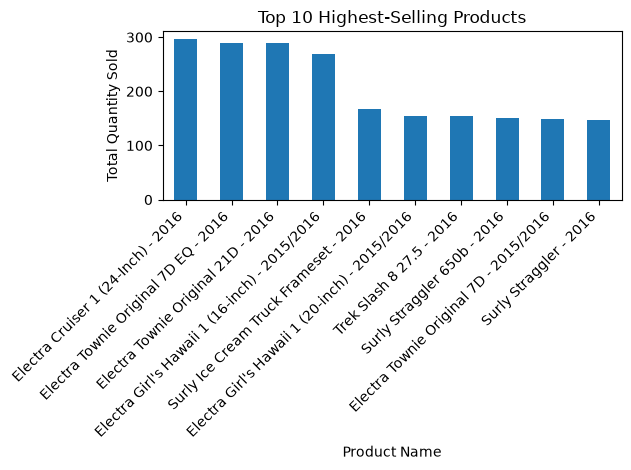

                           product_name  quantity
0    Electra Cruiser 1 (24-Inch) - 2016       296
1  Electra Townie Original 7D EQ - 2016       290
2    Electra Townie Original 21D - 2016       289


In [152]:
import matplotlib.pyplot as plt
top_products = order_items.merge(products[["product_id", "product_name"]], on="product_id")
top_products = top_products.groupby("product_name")["quantity"].sum().sort_values(ascending=False).head(10).reset_index()

top_products.plot(x="product_name", y="quantity", kind="bar", legend=False)
plt.title("Top 10 Highest-Selling Products")
plt.xlabel("Product Name")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
print(top_products.head(3))

## Business Question: Which products have the highest sales volume?

### Business Insight
This chart identifies the top 10 products based on total quantity sold. It helps the business understand which products have the highest customer demand and make better inventory and stock replenishment decisions.

### Key Finding
Electra Cruiser 1 (24-Inch) - 2016 sold the most units (296), followed by Electra Townie Original 7D EQ - 2016 (290) and Electra Townie Original 21D - 2016 (289).

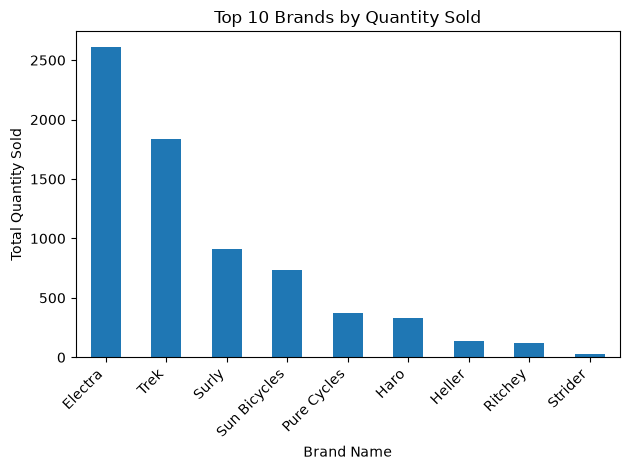

   brand_id  quantity brand_name
0         1      2612    Electra
8         9      1839       Trek
7         8       908      Surly


In [153]:
brand_sales = order_items.merge(
    products[["product_id", "brand_id"]],
    on="product_id"
)

brand_sales = brand_sales.groupby("brand_id")["quantity"].sum().reset_index()

brand_sales = brand_sales.merge(
    brands[["brand_id", "brand_name"]],
    on="brand_id"
)

brand_sales = brand_sales.sort_values("quantity", ascending=False).head(10)

brand_sales.plot(
    x="brand_name",
    y="quantity",
    kind="bar",
    legend=False
)

plt.title("Top 10 Brands by Quantity Sold")
plt.xlabel("Brand Name")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
print(brand_sales.head(3))

## Business Question: Which brands have the highest sales volume?

### Business Insight
This chart ranks the top 10 brands based on the total quantity of products sold. It helps the business compare brand performance and understand which brands have greater customer demand.

### Key Finding
Electra is the top brand with 2,612 units sold, followed by Trek (1,839) and Surly (908).

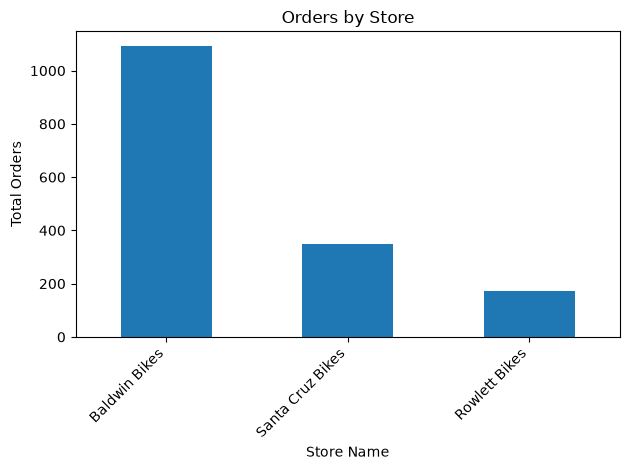

   store_id  total_orders        store_name
1         2          1093     Baldwin Bikes
0         1           348  Santa Cruz Bikes
2         3           174     Rowlett Bikes


In [154]:
store_sales = orders.groupby("store_id")["order_id"].nunique().reset_index(name="total_orders")

store_sales = store_sales.merge(
    stores[["store_id", "store_name"]],
    on="store_id"
)

store_sales = store_sales.sort_values("total_orders", ascending=False)

store_sales.plot(
    x="store_name",
    y="total_orders",
    kind="bar",
    legend=False
)

plt.title("Orders by Store")
plt.xlabel("Store Name")
plt.ylabel("Total Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
print(store_sales)

## Business Question: Which stores receive the most orders?

### Business Insight
This chart compares the total number of orders received by each store. It helps the business understand differences in order volume across store locations.

### Key Finding
Baldwin Bikes received the most orders (1,093), far ahead of Santa Cruz Bikes (348) and Rowlett Bikes (174).

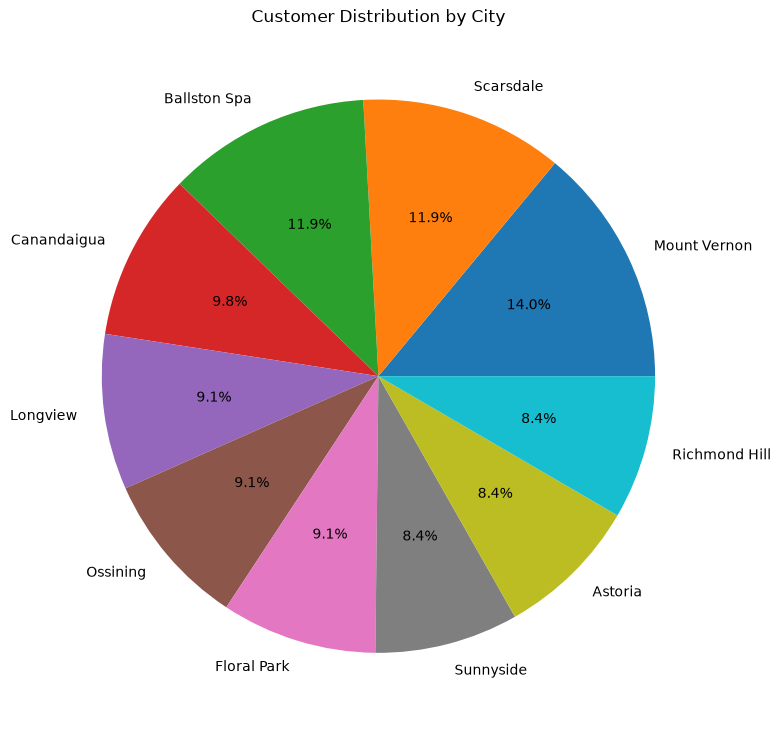

city
Mount Vernon    20
Scarsdale       17
Ballston Spa    17
Name: count, dtype: int64


In [155]:
city_customers = customers["city"].value_counts().head(10)

city_customers.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(8, 8)
)

plt.title("Customer Distribution by City")
plt.ylabel("")
plt.tight_layout()
plt.show()
print(customers["city"].value_counts().head(3))

## Business Question: Which cities have the largest customer base?

### Business Insight
This pie chart shows the percentage distribution of customers across the top 10 cities. It helps the business understand where its customer base is concentrated.

### Key Finding
Mount Vernon has the most customers (20), followed by Scarsdale and Ballston Spa (17 each). Customers are spread across many cities, with no single city dominating.

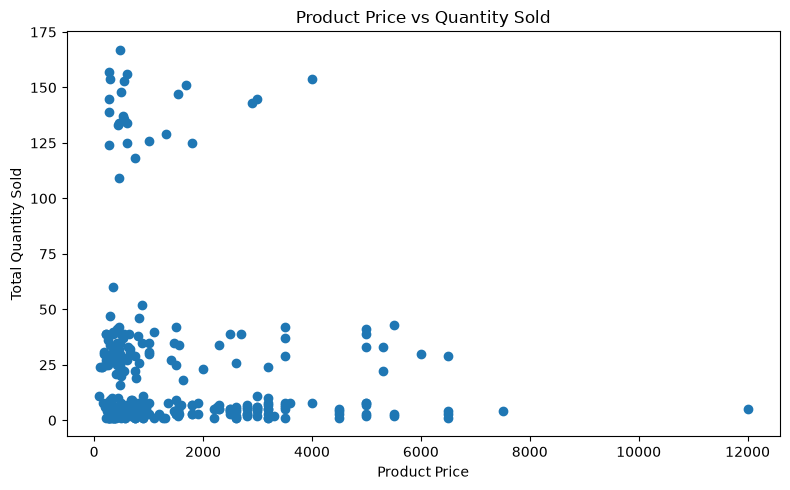

In [156]:
product_sales = order_items.groupby("product_id")["quantity"].sum().reset_index()

product_sales = product_sales.merge(
    products[["product_id", "product_name", "list_price"]],
    on="product_id"
)

plt.figure(figsize=(8, 5))
plt.scatter(product_sales["list_price"], product_sales["quantity"])

plt.title("Product Price vs Quantity Sold")
plt.xlabel("Product Price")
plt.ylabel("Total Quantity Sold")
plt.tight_layout()
plt.show()

## Business Question: Is product price associated with quantity sold?

### Business Insight
This scatter plot compares each product's list price with its total quantity sold. It helps explore whether lower-priced or higher-priced products tend to sell in larger quantities.

### Key Finding
There is a weak negative relationship between price and units sold (correlation about -0.11). Price alone does not explain sales.

Note: these charts include all orders, including rejected ones.

In [157]:
print(order_items["order_id"].isin(orders["order_id"]).all())
print(order_items["product_id"].isin(products["product_id"]).all())
print(products["brand_id"].isin(brands["brand_id"]).all())
print(products["category_id"].isin(categories["category_id"]).all())
stocks["store_id"].isin(stores["store_id"]).all()

True
True
True
True


np.True_